In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df_train = pd.read_csv('/workspaces/seeking-job-change-prediction/data/processed/train.csv')
df_val = pd.read_csv('/workspaces/seeking-job-change-prediction/data/processed/val.csv')

y_train = pd.read_csv('/workspaces/seeking-job-change-prediction/data/processed/y_train.csv').values.ravel()
y_val = pd.read_csv('/workspaces/seeking-job-change-prediction/data/processed/y_val.csv').values.ravel()

## Decision Tree

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [4]:
train_dicts = df_train.to_dict(orient='records')

In [5]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [6]:
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [7]:
for d in [1,2,3,4,5,7,10,15,20,None]:
    dt = DecisionTreeClassifier(max_depth = d)
    dt.fit(X_train,y_train)

    y_pred = dt.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (d, auc))

   1 -> 0.674
   2 -> 0.780
   3 -> 0.795
   4 -> 0.804
   5 -> 0.802
   7 -> 0.794
  10 -> 0.760
  15 -> 0.647
  20 -> 0.617
None -> 0.646


##### so max_depth of 4 is good, with auc of 80.4%. but can consider 3, 4, 5 for further steps

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

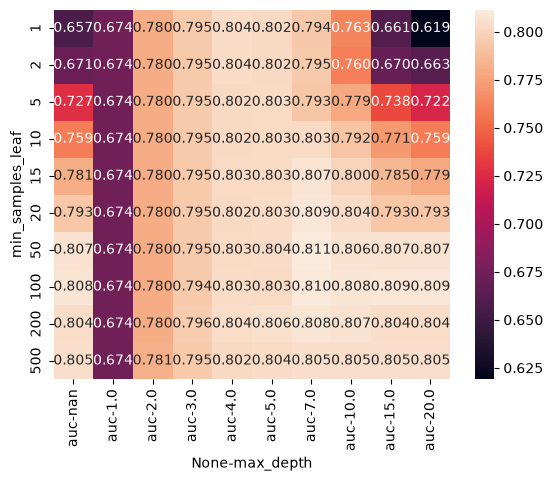

In [8]:
scores = []

for d in [1,2,3,4,5,7,10,15,20,None]:
    for s in [1,2,5,10,15,20,50,100,200,500]:
        dt = DecisionTreeClassifier(max_depth = d, min_samples_leaf=s)
        dt.fit(X_train,y_train)

        y_pred = dt.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d,s,auc))
df_scores = pd.DataFrame(scores, columns = ['max_depth','min_samples_leaf','auc'])
df_scores.sort_values(by='auc',ascending = False)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(5)
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

##### seems that max_depth=7 and min_sample_leaf=50 produces max auc of 81.1%

## Random Forest

In [9]:
from sklearn.ensemble import RandomForestClassifier

In [10]:
rf = RandomForestClassifier(n_estimators=10,random_state=1) # n_estimators = number of models we want to use
rf.fit(X_train,y_train)

y_pred = rf.predict_proba(X_val)[:,1]
roc_auc_score(y_val, y_pred)

0.7853717969015863

In [11]:
for n in range(10,201,10):
    rf = RandomForestClassifier(n_estimators=n,random_state=2)
    rf.fit(X_train,y_train)

    y_pred = rf.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (n, auc))

  10 -> 0.784
  20 -> 0.798
  30 -> 0.803
  40 -> 0.804
  50 -> 0.805
  60 -> 0.806
  70 -> 0.807
  80 -> 0.805
  90 -> 0.806
 100 -> 0.806
 110 -> 0.805
 120 -> 0.806
 130 -> 0.805
 140 -> 0.806
 150 -> 0.806
 160 -> 0.805
 170 -> 0.805
 180 -> 0.805
 190 -> 0.805
 200 -> 0.806


In [12]:
for d in [5,10,15,20,50]:
    rf = RandomForestClassifier(n_estimators=70,max_depth=d, random_state=2)
    rf.fit(X_train,y_train)

    y_pred = rf.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.6f' % (d, auc))

   5 -> 0.808832
  10 -> 0.808162
  15 -> 0.811764
  20 -> 0.811762
  50 -> 0.804654


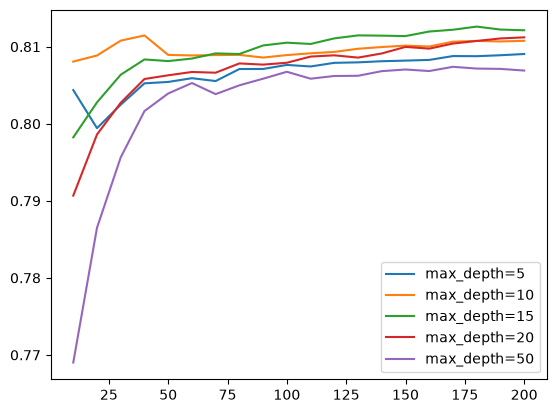

In [13]:
scores = []

for d in [5,10,15,20,50]:
	for n in range(10,201,10):
		rf= RandomForestClassifier(n_estimators=n, max_depth=d,random_state=1)
		rf.fit(X_train,y_train)
		
		y_pred = rf.predict_proba(X_val)[:,1]
		auc = roc_auc_score(y_val, y_pred)
		scores.append((d,n,auc))

df_scores = pd.DataFrame(scores,columns=['max_depth','n_estimators','auc'])
for d in [5,10,15,20,50]:
	df_subset = df_scores[df_scores.max_depth == d]
	plt.plot(df_subset.n_estimators,df_subset.auc, label = 'max_depth=%d' % d)
plt.legend()

##### n_estimator=175, max_depth=15, for auc=81.5%

In [14]:
max_depth = 15

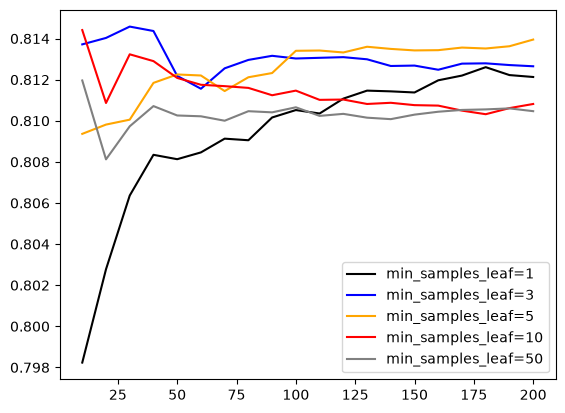

In [15]:
scores = []
for s in [1,3,5,10,50]:
	for n in range(10,201,10):
		rf= RandomForestClassifier(n_estimators=n, max_depth=max_depth,min_samples_leaf=s,random_state=1)
		rf.fit(X_train,y_train)
		
		y_pred = rf.predict_proba(X_val)[:,1]
		auc = roc_auc_score(y_val, y_pred)
		scores.append((s,n,auc))

df_scores = pd.DataFrame(scores,columns=['min_samples_leaf','n_estimators','auc'])

colors = ['black','blue','orange','red','grey']
min_samples_leaf = [1,3,5,10,50]
for s, col in list(zip(min_samples_leaf,colors)):
	df_subset=df_scores[df_scores.min_samples_leaf==s]
	plt.plot(df_subset.n_estimators,df_subset.auc, color = col, label = 'min_samples_leaf=%d' % s)
plt.legend()

In [17]:
df_scores.sort_values('auc', ascending=False).head(10).reset_index(drop=True)

,min_samples_leaf,n_estimators,auc
0,3,30,0.814583
1,10,10,0.814414
2,3,40,0.814368
3,3,20,0.814031
4,5,200,0.813951
5,3,10,0.813718
6,5,190,0.813626
7,5,130,0.813602
8,5,170,0.813562
9,5,180,0.813518


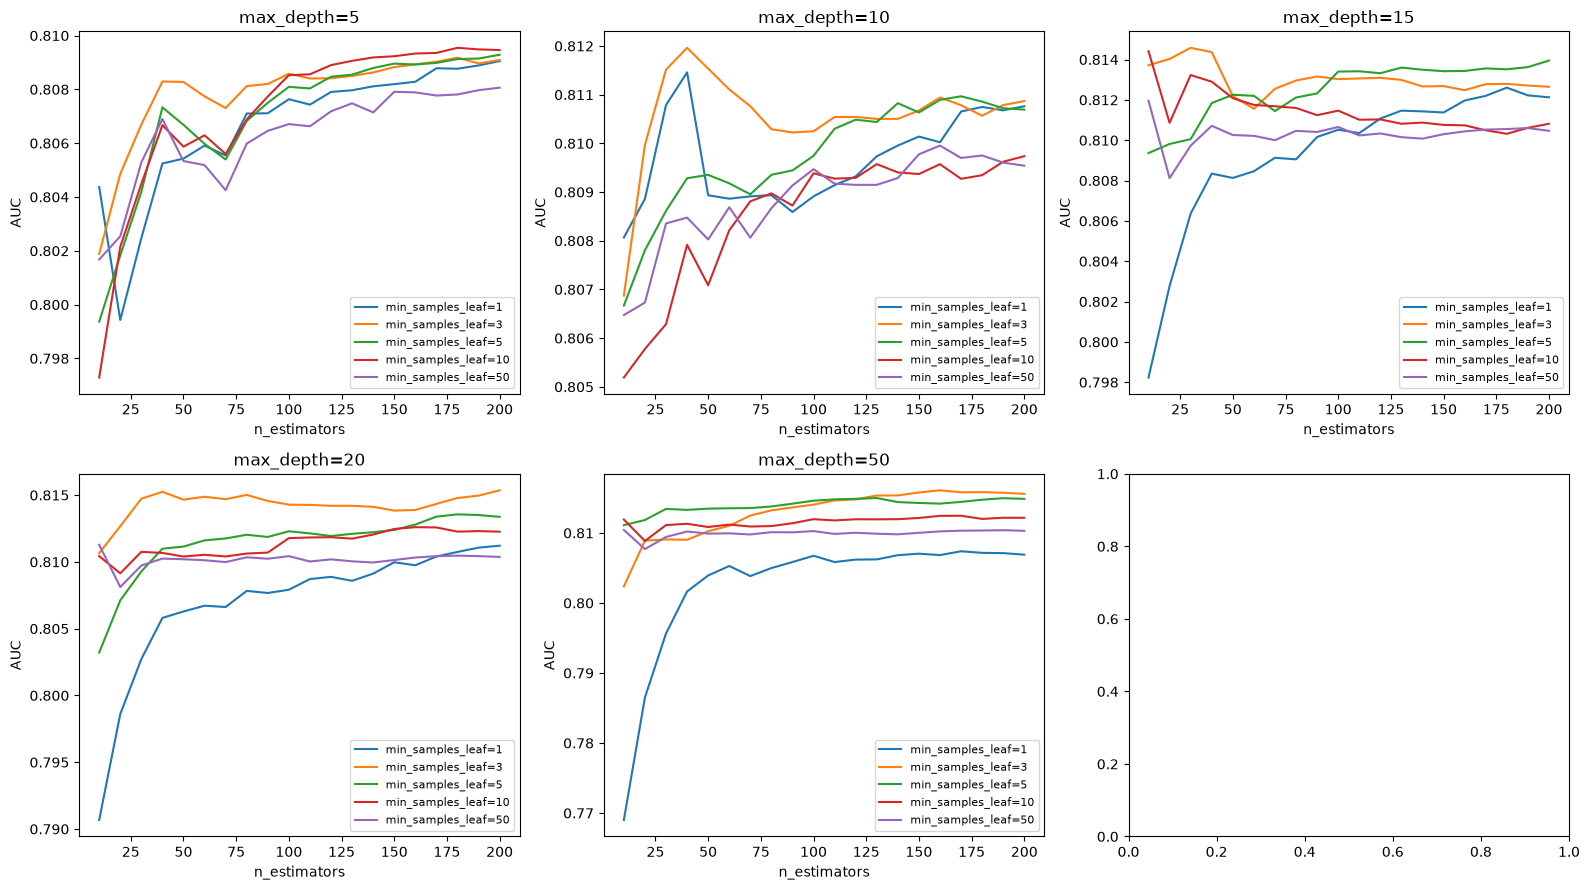

In [18]:
scores = []

for d in [5, 10, 15, 20, 50]:
    for s in [1, 3, 5, 10, 50]:
        for n in range(10, 201, 10):

            rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=d,
                min_samples_leaf=s,
                random_state=1
            )

            rf.fit(X_train, y_train)

            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)

            scores.append((d, s, n, auc))

df_scores = pd.DataFrame(
    scores,
    columns=['max_depth', 'min_samples_leaf', 'n_estimators', 'auc']
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, d in enumerate([5, 10, 15, 20, 50]):
    ax = axes[i]
    df_depth = df_scores[df_scores.max_depth == d]
    for s in [1, 3, 5, 10, 50]:
        df_subset = df_depth[df_depth.min_samples_leaf == s]
        ax.plot(df_subset.n_estimators,df_subset.auc,label='min_samples_leaf=%d' % s)

    ax.set_title('max_depth=%d' % d)
    ax.set_xlabel('n_estimators')
    ax.set_ylabel('AUC')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [19]:
df_scores.sort_values('auc', ascending=False).head(10).reset_index(drop=True)

,max_depth,min_samples_leaf,n_estimators,auc
0,50,3,160,0.816092
1,50,3,180,0.815835
2,50,3,170,0.815809
3,50,3,150,0.815788
4,50,3,190,0.815744
5,50,3,200,0.815587
6,50,3,140,0.815360
7,20,3,200,0.815360
8,50,3,130,0.815349
9,20,3,40,0.815248


##### max_depth=50, min_samples_leaf=3, n_estimators=160 => auc=81.6